<a href="https://colab.research.google.com/github/wararit-panichkitkosolkul/bike-sharing-DS512/blob/main/Bike_Sharing_Homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **DS514/515: Data Science**

## **ตัวแบบการเรียนรู้ของเครื่องเบื้องต้นเพื่อทำนายจำนวนครั้งการเช่าจักรยานสาธารณะรายวัน**
การศึกษาตัวแบบการเรียนรู้ของเครื่อง (Machine Learning) เบื้องต้น ในการพยากรณ์จำนวนครั้งการเช่าจักรยานสาธารณะรายวัน โดยวิเคราะห์ร่วมกับตัวแปรสภาพอากาศและแนวโน้มเชิงเวลา

# สมาชิกในกลุ่ม
1. นายก้องภพ สายสุด (รหัสนิสิต 69199160398)
2. นายพศวีร์ คอนจอหอ  (รหัสนิสิต 69199160411)
3. นายวราฤทธิ์ พานิชกิจโกศลกุล  (รหัสนิสิต 69199160420)

# L0 - Data Preparation and Data Claning

In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
#การ import ไลบารีที่เกี่ยวข้อง
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels.api as sm
from scipy.linalg import lstsq

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import plot_tree

In [58]:
#การอ่านแฟ้มข้อมูล
bike = pd.read_csv('/content/drive/MyDrive/Bike_Sharing_Data.csv')

Data Dictionary
| ตัวแปร | ความหมาย | ชนิดข้อมูล | รหัส / หน่วย / รายละเอียด |
|---|---|---|---|
| `instant` | ลำดับระเบียนข้อมูล | จำนวนเต็ม — ตัวระบุ | ใช้ระบุแถวข้อมูล |
| `dteday` | วันที่บันทึกข้อมูล | วันที่ | รูปแบบ `YYYY-MM-DD` |
| `season` | ฤดูกาล | หมวดหมู่ | 1 = ฤดูหนาว, 2 = ฤดูใบไม้ผลิ, 3 = ฤดูร้อน, 4 = ฤดูใบไม้ร่วง |
| `yr` | ปีที่บันทึกข้อมูล | หมวดหมู่ | 0 = ค.ศ. 2011, 1 = ค.ศ. 2012 |
| `mnth` | เดือน | หมวดหมู่ | 1 = มกราคม ถึง 12 = ธันวาคม |
| `holiday` | สถานะวันหยุด | ทวิภาค | 0 = ไม่ใช่วันหยุด, 1 = วันหยุด |
| `weekday` | วันในสัปดาห์ | หมวดหมู่ | รหัส 0–6; ตรวจสอบชื่อวันเทียบกับ `dteday` |
| `workingday` | สถานะวันทำงาน | ทวิภาค | 1 = วันทำงาน, 0 = วันเสาร์–อาทิตย์หรือวันหยุด |
| `weathersit` | ประเภทสภาพอากาศ | หมวดหมู่ | 1 = แจ่มใสหรือมีเมฆบางส่วน; 2 = มีหมอกบางหรือหมอกร่วมกับเมฆ; 3 = ฝนหรือหิมะเล็กน้อย อาจมีพายุฝนฟ้าคะนอง; 4 = ฝนหนักร่วมกับพายุหรือเม็ดน้ำแข็ง หรือหิมะร่วมกับหมอก |
| `temp` | อุณหภูมิที่ปรับสเกลแล้ว | ตัวเลขทศนิยม | ค่า normalized; ตรวจสอบสูตรก่อนแปลงกลับเป็น °C |
| `atemp` | อุณหภูมิที่ร่างกายรู้สึก ซึ่งปรับมาตราส่วนแล้ว | ตัวเลขทศนิยม | ค่า normalized; ตรวจสอบสูตรก่อนแปลงกลับเป็น °C |
| `hum` | ความชื้นสัมพัทธ์ที่ปรับสเกลแล้ว | ตัวเลขทศนิยม | ความชื้นสัมพัทธ์ (%) ÷ 100 |
| `windspeed` | ความเร็วลมที่ปรับมาตราส่วนแล้ว | ตัวเลขทศนิยม | ความเร็วลมเดิม ÷ 67 |
| `casual` | จำนวนครั้งการเช่าของผู้ใช้ทั่วไป | จำนวนเต็ม | ครั้งต่อวัน |
| `registered` | จำนวนครั้งการเช่าของสมาชิก | จำนวนเต็ม | ครั้งต่อวัน |
| `cnt` | จำนวนครั้งการเช่า (ตัวแปรเป้าหมาย) | จำนวนเต็ม | ครั้งต่อวัน; `cnt = casual + registered` |

การวิเคราะห์ข้อมูลเชิงสำรวจ (EDA) เบื้องต้น

In [ ]:
# ดูข้อมูลเบื้องต้น
print(bike.head())

# ตรวจสอบขนาดข้อมูล
print(bike.shape)

# ตรวจสอบชนิดข้อมูล
print(bike.info())

   instant    dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  1/1/2011       1   0     1        0        6           0   
1        2  2/1/2011       1   0     1        0        0           0   
2        3  3/1/2011       1   0     1        0        1           1   
3        4  4/1/2011       1   0     1        0        2           1   
4        5  5/1/2011       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   0.160296     108        1454   
4           1  0.226957  0.229270  0.436957   0.186900      82        1518   

    cnt  
0   985  
1   801  
2  1349  
3  1562  
4  1600  
(731, 16)
<class 'pandas.core.frame.Da

In [ ]:
#เปลี่ยนชนิดของตัวแปร yr จาก int ให้เป็น category
bike['yr'] = bike['yr'].astype('category')

#แปลงข้อความให้เป็นข้อมูลประเภทวันที่
bike['dteday'] = pd.to_datetime(bike['dteday'], dayfirst=True)

#ดึงปีจากวันที่ แล้วสร้างเป็นคอลัมน์ใหม่ชื่อ year
bike['year'] = bike['dteday'].dt.year

#เปลี่ยนชนิดของตัวแปร year จาก int ให้เป็น category
bike['year'] = bike['year'].astype('category')

#เปลี่ยนชนิดของตัวแปร season จาก int ให้เป็น category
bike['season'] = bike['season'].astype('category')

#เปลี่ยนชนิดของตัวแปร mnth จาก int ให้เป็น category
bike['mnth'] = bike['mnth'].astype('category')

#เปลี่ยนชนิดของตัวแปร holiday จาก int ให้เป็น bool
bike['holiday'] = bike['holiday'].astype('bool')

#เปลี่ยนชนิดของตัวแปร weekday จาก int ให้เป็น category
bike['weekday'] = bike['weekday'].astype('category')

#เปลี่ยนชนิดของตัวแปร working จาก int ให้เป็น bool
bike['workingday'] = bike['workingday'].astype('bool')

#เปลี่ยนชนิดของตัวแปร weathersit จาก int ให้เป็น category
bike['weathersit'] = bike['weathersit'].astype('category')

In [ ]:
#ตรวจสอบว่า แต่ละตัวแปรมีค่า null หรือไม่
print(bike.isnull().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
year          0
dtype: int64


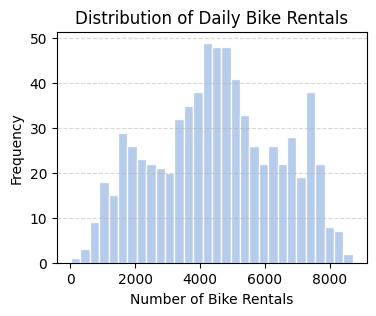

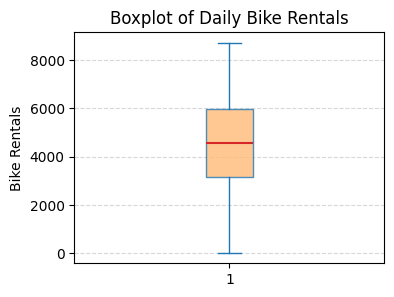

In [ ]:
#Histogram ของจำนวนการเช่าจักรยาน
plt.figure(figsize = [4,3])
plt.hist(bike['cnt'], bins=30, color='#aec7e8', edgecolor='white', alpha=0.9)
plt.xlabel('Number of Bike Rentals')
plt.ylabel('Frequency')
plt.title('Distribution of Daily Bike Rentals')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

#Boxplot ของจำนวนการเช่าจักรยาน
plt.figure(figsize = [4,3])
plt.boxplot(bike['cnt'], patch_artist=True,
            boxprops=dict(facecolor='#ffbb78', color='#1f77b4', alpha=0.8),
            capprops=dict(color='#1f77b4'),
            whiskerprops=dict(color='#1f77b4'),
            flierprops=dict(marker='o', markerfacecolor='#ff9896', markersize=6, linestyle='none'),
            medianprops=dict(color='#d62728', linewidth=1.5))
plt.ylabel('Bike Rentals')
plt.title('Boxplot of Daily Bike Rentals')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# ดูภาพรวมของตัวแปรเชิงปริมาณ
bike.describe()

,instant,dteday,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


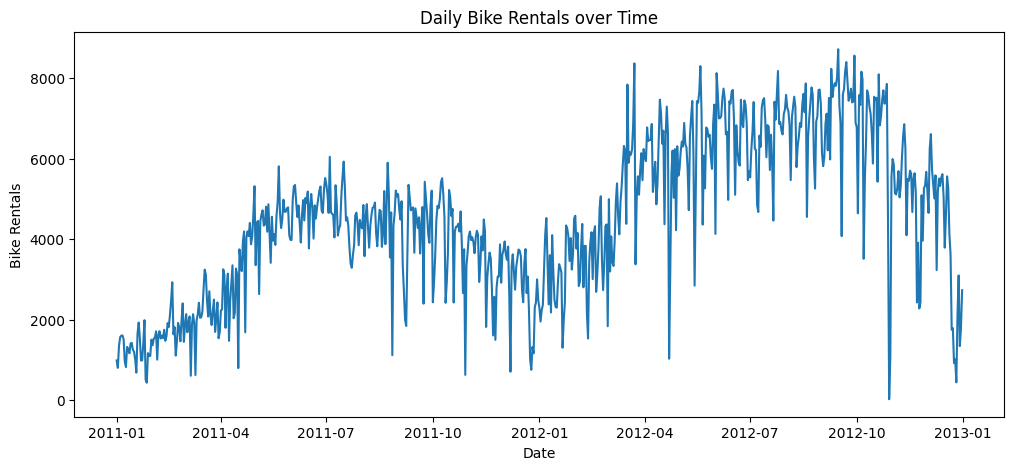

In [ ]:
#พิจารณาแนวโน้มของจำนวนครั้งการเช่าจักรยานตามลำดับเวลา
plt.figure(figsize=(12, 5))
plt.plot(bike['dteday'], bike['cnt'])
plt.xlabel('Date')
plt.ylabel('Bike Rentals')
plt.title('Daily Bike Rentals over Time')
plt.show()

Correlation Analysis

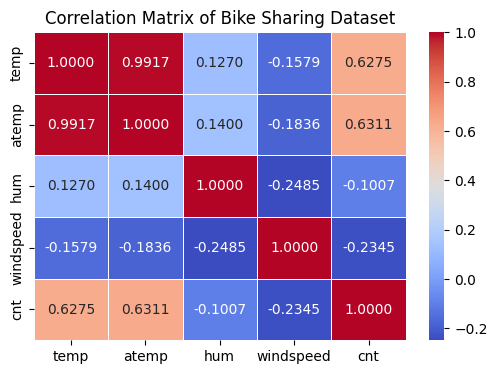

In [ ]:
numeric_vec = ['temp', 'atemp', 'hum', 'windspeed',  'cnt']

correlation_matrix = bike[numeric_vec].corr()

# Plot the heatmap of the correlation matrix with 4 decimal places
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, fmt='.4f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix of Bike Sharing Dataset')
plt.show()

ผลการวิเคราะห์ค่าสัมประสิทธิ์สหสัมพันธ์ของเพียร์สันพบว่า อุณหภูมิ (temp) และอุณหภูมิที่ผู้ใช้รับรู้ (atemp) มีความสัมพันธ์เชิงบวกกับจำนวนการเช่าจักรยาน (cnt) ในระดับปานกลางถึงค่อนข้างสูง โดยมีค่าสัมประสิทธิ์สหสัมพันธ์เท่ากับ 0.6275 และ 0.6311 ตามลำดับ ขณะที่ความชื้น (hum) และความเร็วลม (windspeed มีความสัมพันธ์เชิงลบกับจำนวนการเช่า โดยมีค่าสัมประสิทธิ์เท่ากับ -0.1007 และ -0.2345 ตามลำดับ

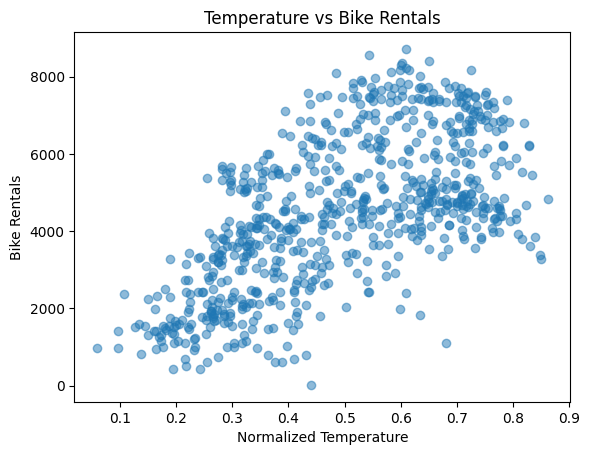

In [ ]:
#Scatter Plot ระหว่างอุณหภูมิกับจำนวนการเช่า
plt.scatter(bike['temp'], bike['cnt'], alpha=0.5)

plt.xlabel('Normalized Temperature')
plt.ylabel('Bike Rentals')
plt.title('Temperature vs Bike Rentals')
plt.show()

Data Preprocessing

In [ ]:
# การกำหนดคอลัมน์ตัวแปรเชิงกลุ่มและตัวแปรต่อเนื่อง
categorical_columns = ['season','yr','mnth','holiday','weekday','workingday','weathersit']
continuous_columns = ['temp','hum','windspeed']

In [ ]:
# การปรับสเกลตัวแปรต่อเนื่องด้วย MinMaxScaler
scaler = MinMaxScaler()
encoder = OneHotEncoder(sparse_output=False)

In [ ]:
# การเข้ารหัส (Encoding) ตัวแปรเชิงกลุ่มด้วย OneHotEncoder
x_scaled = scaler.fit_transform(bike[continuous_columns])
x_encoded = encoder.fit_transform(bike[categorical_columns])

In [ ]:
# การรวมข้อมูลตัวแปรต่อเนื่องที่ปรับสเกลแล้วกับข้อมูลตัวแปรเชิงกลุ่มที่เข้ารหัสแล้ว
x_combined = pd.concat([pd.DataFrame(x_scaled),pd.DataFrame(x_encoded)],axis=1)
y = bike['cnt']

# L9.1 - Linear Regression Model

สร้างโมเดลจากข้อมูลทั้งหมด

In [ ]:
# 1. สร้างโมเดล Linear Regression
lm_full = LinearRegression()
lm_full.fit(x_combined, y)

# 2. ทำนายผลลัพธ์
y_pred_full = lm_full.predict(x_combined)

# 3. ประเมินประสิทธิภาพ
rmse_full = np.sqrt(mean_squared_error(y, y_pred_full))
r2_full = r2_score(y, y_pred_full)

print("=== ประสิทธิภาพของ Linear Regression Model ===")
print(f"RMSE     : {rmse_full:.6f}")
print(f"R-square : {r2_full:.6f}")

=== ประสิทธิภาพของ Linear Regression Model ===
RMSE     : 754.634362
R-square : 0.848045


#L9.2 - Regularized Regression Model (Ridge Regression Model)

In [ ]:
# กำหนดค่า alpha ที่ต้องการทดสอบ 6 ระดับ
alphas = [0.1, 0.5, 1, 5, 10, 20]

print("=== การเปรียบเทียบประสิทธิภาพของ Ridge Regression Model ตามค่า Alpha ===\n")

for alpha in alphas:
    # 1. สร้างโมเดล Ridge Regression
    rdg = Ridge(alpha=alpha)
    rdg.fit(x_combined, y)

    # 2. ทำนายผลลัพธ์
    y_pred_rdg = rdg.predict(x_combined)

    # 3. ประเมินประสิทธิภาพ
    rmse_rdg = np.sqrt(mean_squared_error(y, y_pred_rdg))
    r2_rdg = r2_score(y, y_pred_rdg)

    print(f"Alpha: {alpha}")
    print(f"RMSE     : {rmse_rdg:.6f}")
    print(f"R-square : {r2_rdg:.6f}")
    print("-" * 40)

=== การเปรียบเทียบประสิทธิภาพของ Ridge Regression ตามค่า Alpha ===

Alpha: 0.1
RMSE     : 754.658197
R-square : 0.848036
----------------------------------------
Alpha: 0.5
RMSE     : 755.131638
R-square : 0.847845
----------------------------------------
Alpha: 1
RMSE     : 756.270633
R-square : 0.847386
----------------------------------------
Alpha: 5
RMSE     : 770.259662
R-square : 0.841688
----------------------------------------
Alpha: 10
RMSE     : 787.540264
R-square : 0.834505
----------------------------------------
Alpha: 20
RMSE     : 817.551789
R-square : 0.821651
----------------------------------------


=== คำอธิบายผลลัพธ์ Ridge Regression Model ===
1. ผลกระทบของค่า Alpha (Regularization strength):
   - เมื่อค่า Alpha เพิ่มขึ้น (จาก 0.1 ไปจนถึง 20) จะพบว่าค่า RMSE มีแนวโน้มเพิ่มขึ้นเรื่อยๆ (จาก 754.65 -> 817.55)
   - ในทางกลับกัน ค่า R-squared จะค่อยๆ ลดลง (จาก 0.8480 -> 0.8216)

2. การวิเคราะห์โมเดลที่ดีที่สุด:
   - โมเดลที่ค่า Alpha = 0.1 ให้ประสิทธิภาพดีที่สุดในชุดข้อมูลนี้ (Overall set) โดยมีค่า RMSE ต่ำที่สุดที่ประมาณ 754.6582 และมีค่า R-squared สูงสุดที่ประมาณ 0.8480
   - ค่า R-squared ที่ 0.8480 หมายความว่า ตัวแปรอิสระในแบบจำลองนี้สามารถอธิบายความผันแปรของจำนวนการเช่าจักรยาน (cnt) ได้ถึง 84.80%


# L10 - Decision Tree Regression Model

In [ ]:
# กำหนดค่า max_depth ที่ต้องการทดสอบ 6 ระดับ สำหรับ Decision Tree Regression
depths = [2, 3, 5, 8, 10, 15]

print("=== การเปรียบเทียบประสิทธิภาพของ Decision Tree Regression ตามค่า max_depth ===\n")

for depth in depths:
    # 1. สร้างโมเดล Decision Tree Regressor ตาม max_depth ที่กำหนด
    dt_model = DecisionTreeRegressor(max_depth=depth, min_samples_split=10, random_state=42)
    dt_model.fit(x_combined, y)

    # 2. ทำนายผลลัพธ์
    y_pred_dt = dt_model.predict(x_combined)

    # 3. ประเมินประสิทธิภาพ
    rmse_dt = np.sqrt(mean_squared_error(y, y_pred_dt))
    r2_dt = r2_score(y, y_pred_dt)

    print(f"Max Depth: {depth}")
    print(f"RMSE     : {rmse_dt:.6f}")
    print(f"R-square : {r2_dt:.6f}")
    print("-" * 40)

=== การเปรียบเทียบประสิทธิภาพของ Decision Tree Regression ตามค่า max_depth ===

Max Depth: 2
RMSE     : 1090.576955
R-square : 0.682639
----------------------------------------
Max Depth: 3
RMSE     : 886.095363
R-square : 0.790492
----------------------------------------
Max Depth: 5
RMSE     : 687.277418
R-square : 0.873961
----------------------------------------
Max Depth: 8
RMSE     : 520.058716
R-square : 0.927832
----------------------------------------
Max Depth: 10
RMSE     : 464.842092
R-square : 0.942343
----------------------------------------
Max Depth: 15
RMSE     : 400.459959
R-square : 0.957208
----------------------------------------


=== คำอธิบายผลลัพธ์ของ Decision Tree Regression Model ===
1. อิทธิพลของความลึกของต้นไม้ (Max Depth Effect):
   - เมื่อความลึกของต้นไม้ (Max Depth) เพิ่มขึ้นเรื่อยๆ จะพบว่าค่า RMSE ลดลงอย่างรวดเร็ว (จาก 1090.5769 ที่ระดับ 2 ลดเหลือเพียง 400.4600 ที่ระดับ 15)
   - ขณะเดียวกันค่า R-squared มีทิศทางเพิ่มขึ้นชัดเจน (จาก 0.6826 ไปจนถึง 0.9572) บ่งชี้ว่าตัวแบบอธิบายความผันแปรของข้อมูลได้เกือบสมบูรณ์

2. ข้อควรระวังเรื่อง Overfitting:
   - การที่ค่า RMSE บนข้อมูลชุดเดียวกันต่ำลงมากและการที่ R-squared พุ่งสูงถึง 95.7% ณ ระดับความลึกที่ 15 อาจเป็นผลมาจากโครงสร้างต้นไม้ที่ลึกและซับซ้อนเกินไป (Overfitting)
   - ในทางปฏิบัติจริง หากความลึกมากเกินไป (เช่น 10 หรือ 15) ต้นไม้จะทำการแบ่งย่อยเพื่อเรียนรู้ Noise ในข้อมูล ทำให้เมื่อนำไปพยากรณ์ข้อมูลใหม่ (Test Set) อาจมีประสิทธิภาพที่แย่ลงได้มาก


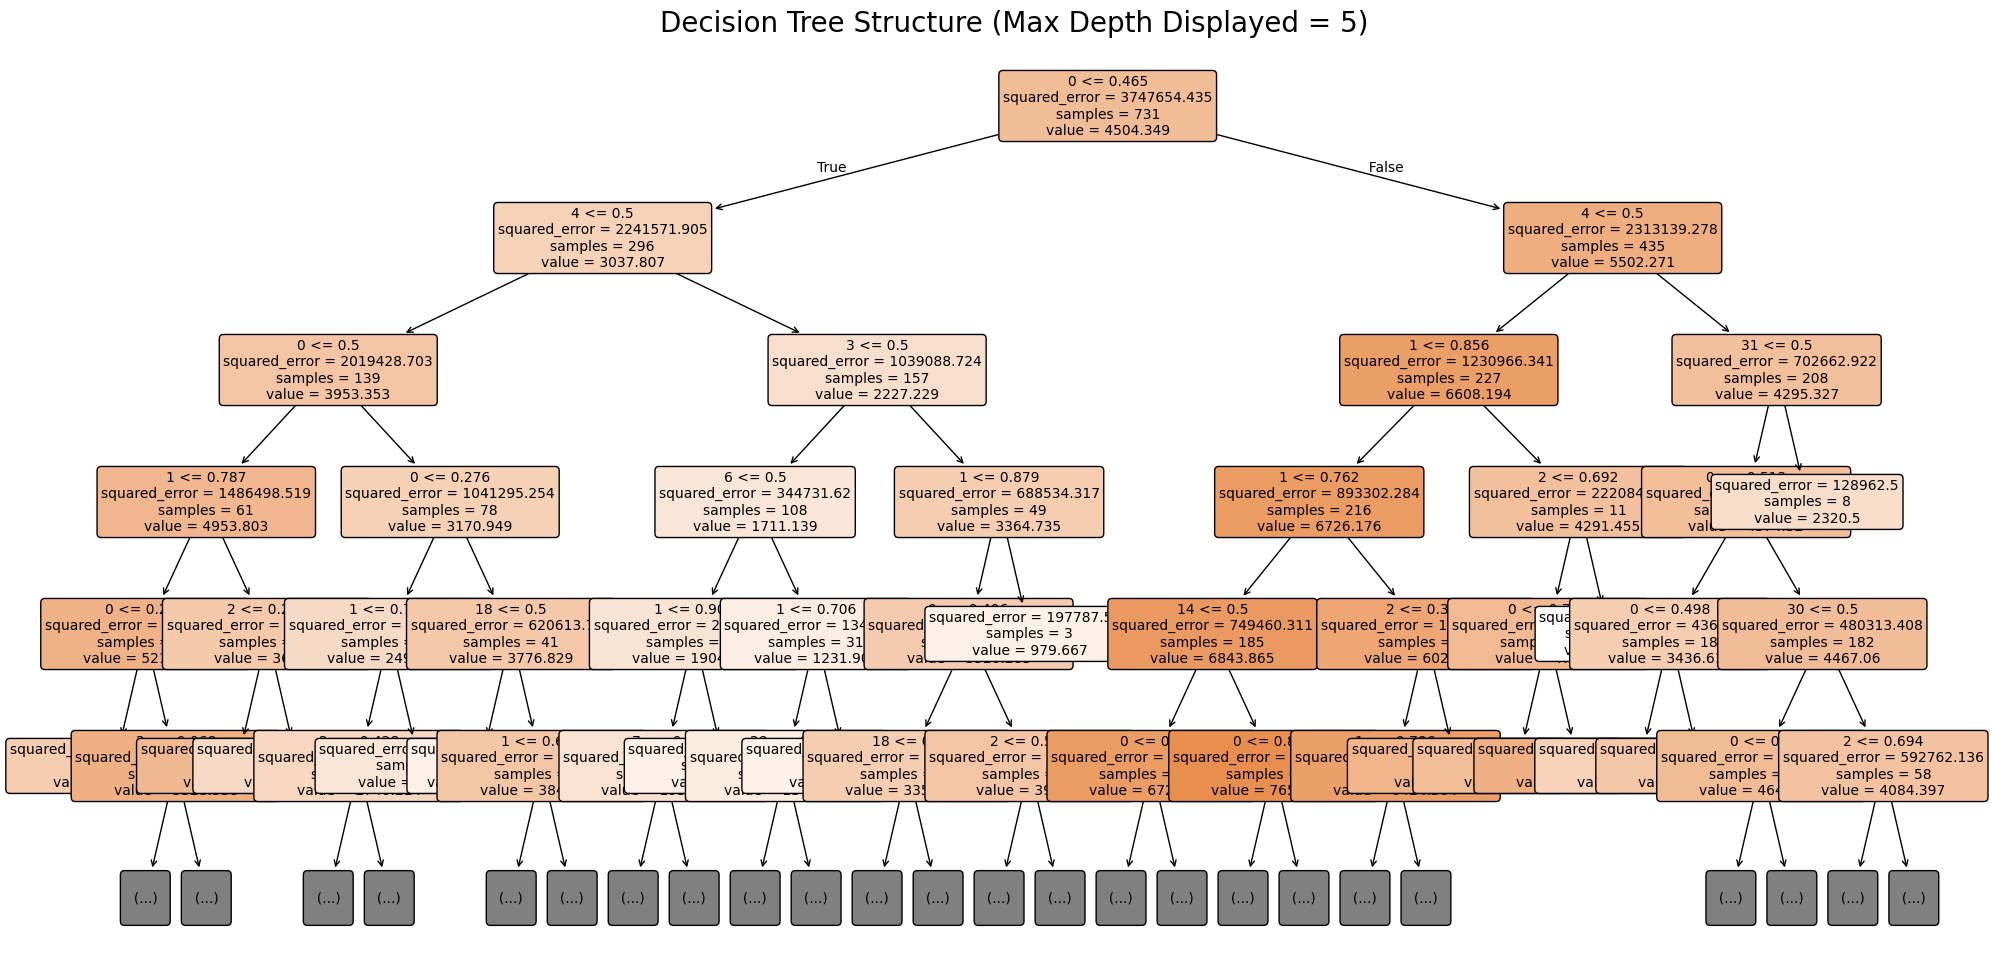

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24, 12))

# แปลงชื่อคอลัมน์ของ X_train เป็น string เพื่อใช้เป็น feature_names
feature_names_list = [str(col) for col in x_combined.columns]

# วาดแผนภาพต้นไม้
plot_tree(dt_model, feature_names=feature_names_list, filled=True,
          rounded=True, fontsize=10, max_depth=5)

plt.title("Decision Tree Structure (Max Depth Displayed = 5)", fontsize=20)
plt.show()

# L11.1 - Data Spliting

In [61]:
# การรวมข้อมูลตัวแปรต่อเนื่องที่ปรับสเกลแล้วกับข้อมูลตัวแปรเชิงกลุ่มที่เข้ารหัสแล้ว
x_combined = pd.concat([pd.DataFrame(x_scaled),pd.DataFrame(x_encoded)],axis=1)
y_train = bike['cnt']

In [62]:
# การแบ่งชุดข้อมูลเป็นชุดฝึกสอนและชุดทดสอบ (Training and Testing sets) ในอัตราส่วน 80:20 ตามลำดับเวลา (shuffle=False)
X_train, X_test, y_train, y_test = train_test_split(x_combined, y_train, test_size=0.2, shuffle=False)

Linear Regression Model (Train : Test)

In [65]:
# 1. สร้างและฝึกสอนโมเดลเชิงเส้น
lm_full = LinearRegression()
lm_full.fit(X_train, y_train)

# 2. ทำนายผลลัพธ์บนชุดข้อมูล Train และ Test
y_train_pred_full = lm_full.predict(X_train)
y_test_pred_full = lm_full.predict(X_test)

# 3. ประเมินประสิทธิภาพบนชุดข้อมูล Train
rmse_train_full = root_mean_squared_error(y_train, y_train_pred_full)
r2_train_full = r2_score(y_train, y_train_pred_full)

# 4. ประเมินประสิทธิภาพบนชุดข้อมูล Test
rmse_test_full = root_mean_squared_error(y_test, y_test_pred_full)
r2_test_full = r2_score(y_test, y_test_pred_full)

print("=== ประสิทธิภาพของ Linear Regression Model ===")
print(f"Train RMSE     : {rmse_train_full:.6f}")
print(f"Train R-square : {r2_train_full:.6f}")
print(f"-------------------------------------------------")
print(f"Test RMSE      : {rmse_test_full:.6f}")
print(f"Test R-square  : {r2_test_full:.6f}")

=== ประสิทธิภาพของ Linear Regression Model ===
Train RMSE     : 680.198349
Train R-square : 0.855173
-------------------------------------------------
Test RMSE      : 1103.666864
Test R-square  : 0.653383


 **สรุปผลประสิทธิภาพของตัวแบบ Linear Regression (Train : Test)**

จากผลการทดสอบเปรียบเทียบประสิทธิภาพของแบบจำลองเชิงเส้น (Linear Regression) ระหว่างชุดข้อมูลฝึกสอน (Train Set) และชุดข้อมูลทดสอบ (Test Set) ในอัตราส่วน 80:20 (แบ่งข้อมูลตามลำดับเวลา) สามารถสรุปประเด็นสำคัญได้ดังนี้:

1. **ประสิทธิภาพบนชุดข้อมูลฝึกสอน (Train Set):**
   - **Train RMSE** เท่ากับ **680.198349**
   - **Train $R^2$ (R-square)** เท่ากับ **0.855173** (หรือคิดเป็น **85.52%**)
   - บ่งชี้ว่าแบบจำลองสามารถเรียนรู้และอธิบายความผันแปรของจำนวนการเช่าจักรยานในข้อมูลชุด Train ได้เป็นอย่างดี

2. **ประสิทธิภาพบนชุดข้อมูลทดสอบ (Test Set):**
   - **Test RMSE** เท่ากับ **1103.666864** ซึ่งสูงกว่าฝั่ง Train อย่างเห็นได้ชัด (มีความคลาดเคลื่อนในการพยากรณ์เพิ่มขึ้น)
   - **Test $R^2$ (R-square)** ลดลงเหลือ **0.653383** (หรือคิดเป็น **65.34%**)

3. **ข้อสังเกตเชิงลึก (Overfitting):**
   - ผลลัพธ์แสดงให้เห็นถึงความแตกต่างของประสิทธิภาพอย่างชัดเจนระหว่าง Train และ Test ซึ่งเข้าข่ายเกิดปัญหา **Overfitting (การเรียนรู้ดีเกินไป)**
   - เนื่องจากการแบ่งข้อมูลเป็นแบบตามลำดับเวลา (Chronological Split) ข้อมูลในชุด Test (20% หลัง) อาจมีแนวโน้มหรือปัจจัยเชิงฤดูกาลที่เปลี่ยนแปลงไปจากอดีต ส่งผลให้โมเดลที่พยายามปรับค่าให้เข้ากับชุด Train มากเกินไป ไม่สามารถนำไปประยุกต์ใช้ทำนายข้อมูลอนาคต (Test Set) ได้ดีเท่าที่ควร

Ridge Regression Model (Train : Test)

In [68]:
# กำหนดค่า alpha ที่ต้องการทดสอบ 6 ระดับ
alphas = [0.01, 0.1, 0.5, 1, 5, 10]

print("=== การเปรียบเทียบประสิทธิภาพของ Ridge Regression ตามค่า Alpha ===\n")

for alpha in alphas:
    # สร้างและฝึกสอนแบบจำลอง
    rdg = Ridge(alpha=alpha)
    rdg.fit(X_train, y_train)

    # ทำนายผล
    y_train_pred = rdg.predict(X_train)
    y_test_pred = rdg.predict(X_test)

    # คำนวณประสิทธิภาพสำหรับ Train set
    rmse_train = mean_squared_error(y_train, y_train_pred) ** 0.5
    r2_train = r2_score(y_train, y_train_pred)

    # คำนวณประสิทธิภาพสำหรับ Test set
    rmse_test = mean_squared_error(y_test, y_test_pred) ** 0.5
    r2_test = r2_score(y_test, y_test_pred)

    # แสดงผลลัพธ์
    print(f"Alpha: {alpha}")
    print(f"  Train RMSE : {rmse_train:.6f} | Train R-square : {r2_train:.6f}")
    print(f"  Test RMSE  : {rmse_test:.6f} | Test R-square  : {r2_test:.6f}")
    print("-" * 70)

=== การเปรียบเทียบประสิทธิภาพของ Ridge Regression ตามค่า Alpha ===

Alpha: 0.01
  Train RMSE : 680.198603 | Train R-square : 0.855173
  Test RMSE  : 1103.883927 | Test R-square  : 0.653247
----------------------------------------------------------------------
Alpha: 0.1
  Train RMSE : 680.222529 | Train R-square : 0.855163
  Test RMSE  : 1105.808936 | Test R-square  : 0.652037
----------------------------------------------------------------------
Alpha: 0.5
  Train RMSE : 680.698502 | Train R-square : 0.854960
  Test RMSE  : 1113.808619 | Test R-square  : 0.646984
----------------------------------------------------------------------
Alpha: 1
  Train RMSE : 681.836900 | Train R-square : 0.854474
  Test RMSE  : 1122.775308 | Test R-square  : 0.641277
----------------------------------------------------------------------
Alpha: 5
  Train RMSE : 696.023931 | Train R-square : 0.848356
  Test RMSE  : 1174.545942 | Test R-square  : 0.607433
---------------------------------------------------

 **สรุปผลการเปรียบเทียบประสิทธิภาพของ Ridge Regression ตามค่า Alpha (Train : Test)**

จากการทดสอบประสิทธิภาพของตัวแบบ Ridge Regression** ด้วยการปรับเปลี่ยนค่าพารามิเตอร์ควบคุมความซับซ้อน (Regularization Parameter หรือ $\alpha$) ตั้งแต่ 0.01 ถึง 10 บนชุดข้อมูลฝึกสอน (Train) และทดสอบ (Test) ในอัตราส่วน 80:20 ตามลำดับเวลา (Chronological Split) สามารถสรุปได้ดังนี้:

1. **ผลกระทบจากการปรับค่า Alpha (Regularization Effect):**
   - **ฝั่ง Train Set:** เมื่อค่า Alpha เพิ่มขึ้น ค่า Train RMSE จะค่อยๆ เพิ่มขึ้น (จาก 680.19 -> 714.02) และ Train R-square ค่อยๆ ลดลง (จาก 0.8552 -> 0.8404) เนื่องจากตัวแบบโดนจำกัดความสามารถในการ fit ข้อมูลฝึกสอน
   - **ฝั่ง Test Set:** เมื่อค่า Alpha เพิ่มขึ้น ค่า Test RMSE จะเพิ่มสูงขึ้นตามลำดับ (จาก 1103.88 -> 1219.98) และ Test R-square จะลดลง (จาก 0.6532 -> 0.5765)

2. **การเลือกค่า Alpha ที่เหมาะสมที่สุด (Best Model):**
   - **Alpha = 0.01** ให้ผลลัพธ์ที่ดีที่สุดสำหรับข้อมูลชุดนี้:
     - **Train RMSE** : 680.198603 | **Train R-square** : 0.855173 (85.52%)
     - **Test RMSE**  : 1103.883927 | **Test R-square**  : 0.653247 (65.32%)
   - เนื่องจากเมื่อเพิ่มค่า Alpha มากกว่านี้ (เช่น 5 หรือ 10) ประสิทธิภาพทั้งในแง่ของ RMSE และ R-square ในชุดทดสอบ (Test) กลับแย่ลงอย่างชัดเจน ซึ่งชี้ให้เห็นว่าการทำ Regularization ที่เข้มข้นเกินไป ไม่สามารถช่วยลดผลกระทบของความคลาดเคลื่อนจากความผันแปรตามลำดับเวลาในชุดข้อมูลนี้ได้

3. **ข้อสังเกตเพิ่มเติมเกี่ยวกับ Overfitting:**
   - ไม่ว่าจะเลือกใช้ Alpha ใดก็ตาม โมเดลยังมี Gap ของประสิทธิภาพ ระหว่าง Train R-square (85%) และ Test R-square (65%) ค่อนข้างกว้าง ซึ่งเกิดจากการแบ่งข้อมูลตามลำดับเวลา ที่สภาพแวดล้อมและพฤติกรรมการใช้งานในชุดข้อมูล Test (อนาคต) มีความแตกต่างไปจาก Train (อดีต)

Decision Tree Regression Model (Train :Test)

In [71]:
# กำหนดค่า max_depth ที่ต้องการทดสอบ 6 ระดับ สำหรับ Decision Tree Regression
depths = [2, 3, 5, 8, 10, 15]

print("=== การเปรียบเทียบประสิทธิภาพของ Decision Tree Regression ตามค่า max_depth ===\n")

for depth in depths:
    # 1. เทรนโมเดล Decision Tree Regressor ตามความลึกที่กำหนด
    dt_model = DecisionTreeRegressor(max_depth=depth, min_samples_split=10, random_state=333)
    dt_model.fit(X_train, y_train)

    # 2. ทำนายผล
    y_train_pred_dt = dt_model.predict(X_train)
    y_test_pred_dt = dt_model.predict(X_test)

    # 3. คำนวณค่า RMSE
    rmse_train_dt = mean_squared_error(y_train, y_train_pred_dt) ** 0.5
    rmse_test_dt = mean_squared_error(y_test, y_test_pred_dt) ** 0.5

    # 4. คำนวณค่า R-squared
    r2_train_dt = r2_score(y_train, y_train_pred_dt)
    r2_test_dt = r2_score(y_test, y_test_pred_dt)

    # 5. แสดงผลการเปรียบเทียบ
    print(f"Max Depth: {depth}")
    print(f"  Train RMSE : {rmse_train_dt:.4f} | Train R-square : {r2_train_dt:.4f}")
    print(f"  Test RMSE  : {rmse_test_dt:.4f}  | Test R-square  : {r2_test_dt:.4f}")
    print("-" * 70)

=== การเปรียบเทียบประสิทธิภาพของ Decision Tree Regression ตามค่า max_depth ===

Max Depth: 2
  Train RMSE : 964.9995 | Train R-square : 0.7085
  Test RMSE  : 1550.5766  | Test R-square  : 0.3158
----------------------------------------------------------------------
Max Depth: 3
  Train RMSE : 782.3081 | Train R-square : 0.8084
  Test RMSE  : 1309.6325  | Test R-square  : 0.5119
----------------------------------------------------------------------
Max Depth: 5
  Train RMSE : 612.9131 | Train R-square : 0.8824
  Test RMSE  : 1291.8796  | Test R-square  : 0.5251
----------------------------------------------------------------------
Max Depth: 8
  Train RMSE : 439.5929 | Train R-square : 0.9395
  Test RMSE  : 1401.3081  | Test R-square  : 0.4412
----------------------------------------------------------------------
Max Depth: 10
  Train RMSE : 383.9082 | Train R-square : 0.9539
  Test RMSE  : 1326.5733  | Test R-square  : 0.4992
------------------------------------------------------------

**สรุปผลการเปรียบเทียบประสิทธิภาพของ Decision Tree Regression ตามค่า max_depth (Train : Test)**

จากการทดสอบประสิทธิภาพของตัวแบบ Decision Tree Regression ด้วยการปรับค่าความลึกสูงสุดของต้นไม้ตัดสินใจ (max_depth) ตั้งแต่ 2 ถึง 15 บนชุดข้อมูลฝึกสอน (Train) และชุดข้อมูลทดสอบ (Test) ที่แบ่งแบบตามลำดับเวลา (Chronological Split) สามารถสรุปผลการวิเคราะห์ได้ดังนี้:

1. **ผลกระทบของความลึก (max_depth) ต่อความสามารถในการเรียนรู้:**
   - **ฝั่ง Train Set:** เมื่อเพิ่มค่า max_dept (ต้นไม้ซับซ้อนขึ้น) ตัวแบบจะสามารถ fit ข้อมูลฝึกสอนได้ดียิ่งขึ้นอย่างต่อเนื่อง โดยค่า Train RMSE ลดลงจาก 964.9995 เหลือเพียง 347.6699 และ Train R-square เพิ่มขึ้นจาก 0.7085 เป็น 0.9622
   - **ฝั่ง Test Set:** ประสิทธิภาพในชุดทดสอบไม่ได้ดีขึ้นตามความลึกที่เพิ่มขึ้นอย่างไม่มีขอบเขต โดยค่า Test R-square มีค่าสูงสุดอยู่ที่ประมาณ 0.5251 (เมื่อ max_depth = 5) และหลังจากนั้นเมื่อความลึกเพิ่มขึ้นเป็น 8, 10 หรือ 15 ประสิทธิภาพบน Test Set จะเริ่มมีความผันผวนและลดต่ำลงอย่างเห็นได้ชัด

2. **การวิเคราะห์จุดที่เหมาะสมที่สุด (Optimal max_depth):**
   - **max_depth = 5** คือจุดที่เหมาะสมที่สุด (Best Model Trade-off) สำหรับโครงสร้างข้อมูลนี้:
     - **Train RMSE** : 612.9131 | **Train R-square** : 0.8824 (88.24%)
     - **Test RMSE**  : 1291.8796 | **Test R-square**  : 0.5251 (52.51%)
   - ถึงแม้ความแม่นยำด้าน Test Set จะไม่ได้สูงมาก (เนื่องจากข้อจำกัดของการแบ่งข้อมูลเชิงเวลา) แต่เป็นจุดที่ตัวแบบมีความสมดุลและเริ่มป้องกันการเกิด Overfitting ได้ดีที่สุดเมื่อเทียบกับระดับความลึกอื่น

3. **สัญญาณการเกิด Overfitting ที่ชัดเจน:**
   - เมื่อ max_depth $\ge$ 8 ขึ้นไป ตัวแบบจำลองเกิดปัญหา Overfitting อย่างรุนแรง
   - สังเกตได้จากที่ระดับ max_depth = 15 ค่า Train R-square สูงถึง 96.22% (RMSE ต่ำมาก) แต่เมื่อนำไปใช้ทำนายข้อมูลจริงบน Test Set ค่าความแม่นยำ (Test R-square) กลับลดลงอย่างรวดเร็วเหลือเพียง 38.78% และ Test RMSE เพิ่มสูงขึ้นเป็น 1466.7554 เนื่องจากตัวแบบแตกกิ่งก้านลึกเกินไปจนไปจดจำสัญญาณรบกวน (Noise) ของข้อมูลชุดฝึกสอน

**สรุปผลเปรียบเทียบประสิทธิภาพภาพรวมระหว่าง 3 ตัวแบบ (Linear, Ridge, และ Decision Tree Regression)**

เมื่อนำประสิทธิภาพที่ดีที่สุดของแต่ละตัวแบบในการทำนายจำนวนครั้งการเช่าจักรยานรายวันบนชุดข้อมูลทดสอบ (Test Set ที่สัดส่วน 80:20 แบบตามลำดับเวลา) มาเปรียบเทียบกัน จะได้ข้อสรุปที่สำคัญดังตารางต่อไปนี้:

| ตัวแบบ (Model) | ค่าพารามิเตอร์ที่เหมาะสม | Train RMSE | Train $R^2$ | Test RMSE | Test $R^2$ | ลักษณะการทำนายและข้อสังเกต |
|---|---|---|---|---|---|---|
| **1. Linear Regression** | - | **680.1983** | **0.8552** | **1103.6669** | **0.6534** | ประสิทธิภาพดีที่สุดบน Test Set มีความเรียบง่ายสูง |
| **2. Ridge Regression** | $\alpha = 0.01$ | 680.1986 | 0.8552 | 1103.8839 | 0.6532 | ให้ผลใกล้เคียงกับ Linear Regression เนื่องจาก $\alpha$ น้อยมาก |
| **3. Decision Tree** | `max_depth` = 5 | 612.9131 | 0.8824 | 1291.8796 | 0.5251 | เรียนรู้ข้อมูล Train ได้ดีกว่า แต่ผลบน Test Set ต่ำลงอย่างเห็นได้ชัด |

---

**วิเคราะห์เจาะลึก: ตัวแบบไหนดีที่สุด?**

**1. ตัวแบบที่ดีที่สุดในภาพรวม: Linear Regression (หรือ Ridge Regression ที่ $\alpha = 0.01$)**
- **เหตุผล:** เมื่อวัดประสิทธิภาพการนำไปใช้งานจริงกับข้อมูลใหม่ที่โมเดลไม่เคยเห็นในอนาคต (**Test Set**) แบบจำลองเชิงเส้นตรงสามารถทำนายได้แม่นยำที่สุด โดยมีค่า **Test $R^2$ สูงที่สุดที่ 65.34%** และมีความคลาดเคลื่อนต่ำที่สุด (**Test RMSE = 1103.6669**)
- โครงสร้างของสมการเส้นตรงมีระดับความซับซ้อนต่ำ (Low Complexity) ทำให้ไม่เกิดปัญหาความอ่อนไหวต่อสัญญาณรบกวน (Noise) ในอนาคตมากจนเกินไป

**2. ปัญหา Overfitting ที่พบร่วมกันในทุกตัวแบบ:**
- ทุกแบบจำลองมีค่าความแม่นยำลดต่ำลงอย่างมากเมื่อข้ามจาก Train Set ไปยัง Test Set (เช่น R-square จาก ~85% ตกลงไปเหลือ ~65% หรือ ~52%)
- สาเหตุหลักเกิดจากการจัดเตรียมและแบ่งข้อมูลแบบ **Chronological Split (สัดส่วน 80:20 ตามลำดับเวลา)** ซึ่งข้อมูลฝั่ง Test Set (20% หลัง) มีแนวโน้มเชิงเวลา (Time Trend) หรือฤดูกาลที่เปลี่ยนแปลงไปจากอดีตที่ใช้ฝึกสอน ทำให้โมเดลที่เรียนรู้เฉพาะอดีตทำนายอนาคตได้จำกัด

**3. ทำไม Decision Tree Regression ถึงได้ผลลัพธ์แย่ที่สุดในกรณีนี้?**
- แม้ว่า Decision Tree จะสามารถจดจำข้อมูลฝั่ง Train ได้ดีมาก (เมื่อ max_depth = 15 ได้ Train $R^2$ สูงถึง 96.22%) แต่เมื่อเจอกับข้อมูลชุดทดสอบที่มีความต่อเนื่องและมีแนวโน้มตามลำดับเวลาที่แตกต่างออกไป วิธีการแบ่งเกณฑ์ของต้นไม้ตัดสินใจที่มีลักษณะเป็นขั้นบันได (Non-linear Step Function) จะไม่สามารถคาดการณ์ค่าที่อยู่นอกเหนือช่วงความสัมพันธ์เดิมได้ดี ส่งผลให้มีค่า Test $R^2$ ต่ำที่สุด (เพียง 52.51% ที่ความลึกที่ดีที่สุด)

#L11.2 - Data Leakage


**ข้อแนะนำและผลกระทบของการแบ่งข้อมูลต่อปัญหา Data Leakage (การรั่วไหลของข้อมูล)**

**Data Leakage** ในข้อมูลที่มีมิติของเวลา (Time-series / Temporal Data) สามารถเกิดขึ้นได้จาก 2 ปัจจัยหลัก:

1. **Preprocessing Leakage (การรั่วไหลจากขั้นตอนเตรียมข้อมูล):** เกิดจากการนำข้อมูลทั้งหมดมาหาค่าเฉลี่ย, Min/Max (MinMaxScaler) หรือจัดกลุ่ม (OneHotEncoder) ก่อนทำการแบ่งข้อมูลชุดฝึกสอนและชุดทดสอบ ซึ่งแก้ไขได้โดยการแบ่งข้อมูลก่อน แล้วจึงใช้ `.fit_transform()` เฉพาะบนชุด Train เท่านั้น ส่วนชุด Test จะใช้เพียง `.transform()`
2. **Temporal Leakage (การรั่วไหลจากวิธีการแบ่งข้อมูล):** หากเราใช้การสุ่มข้อมูลสลับแถวทั่วทั้งตาราง (Random Split) ข้อมูลจากวันในอนาคตและอดีตจะปะปนกัน ทำให้ตัวแบบแอบเห็นรูปแบบความสัมพันธ์เชิงเวลาของอนาคตในชุด Train ผลประเมินจึงดูดีเกินจริง (Overly Optimistic)

ในการทดลองด้านล่างนี้ เราจะเปรียบเทียบผลลัพธ์ระหว่าง:
* **Random Split (อย่างสุ่ม 80:20):** มีโอกาสเกิด Temporal Leakage สูง
* **Chronological Split (ตามลำดับเวลา 80:20):** จำลองสถานการณ์จริงที่ต้องใช้ข้อมูลอดีตมาพยากรณ์อนาคต

In [81]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

# --- 1. เตรียมข้อมูล ---
bike_split_demo = pd.read_csv('/content/drive/MyDrive/Bike_Sharing_Data.csv')
bike_split_demo['dteday'] = pd.to_datetime(bike_split_demo['dteday'], dayfirst=True)

categorical_cols = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit']
continuous_cols = ['temp', 'hum', 'windspeed']

X_raw_features = bike_split_demo[continuous_cols + categorical_cols]
y_targets = bike_split_demo['cnt']

# ==========================================
# วิธีที่ 1: การแบ่งข้อมูลแบบสุ่ม (Random Split 80:20)
# ==========================================
X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X_raw_features, y_targets, test_size=0.2, random_state=42, shuffle=True
)

# ทำ Preprocessing สำหรับ Random Split แยกกระบวนการเพื่อกัน Leakage
scaler_rand = MinMaxScaler()
enc_rand = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_tr_rand_scaled = scaler_rand.fit_transform(X_tr_rand[continuous_cols])
X_te_rand_scaled = scaler_rand.transform(X_te_rand[continuous_cols])

X_tr_rand_enc = enc_rand.fit_transform(X_tr_rand[categorical_cols])
X_te_rand_enc = enc_rand.transform(X_te_rand[categorical_cols])

X_tr_rand_final = pd.concat([pd.DataFrame(X_tr_rand_scaled), pd.DataFrame(X_tr_rand_enc)], axis=1)
X_te_rand_final = pd.concat([pd.DataFrame(X_te_rand_scaled), pd.DataFrame(X_te_rand_enc)], axis=1)

model_rand = Ridge(alpha=0.1)
model_rand.fit(X_tr_rand_final, y_tr_rand)

pred_tr_rand = model_rand.predict(X_tr_rand_final)
pred_te_rand = model_rand.predict(X_te_rand_final)

# ==========================================
# วิธีที่ 2: การแบ่งข้อมูลตามลำดับเวลา (Chronological Split 80:20)
# ==========================================
X_tr_time, X_te_time, y_tr_time, y_te_time = train_test_split(
    X_raw_features, y_targets, test_size=0.2, shuffle=False
)

# ทำ Preprocessing สำหรับ Chronological Split แยกกระบวนการเพื่อกัน Leakage
scaler_time = MinMaxScaler()
enc_time = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_tr_time_scaled = scaler_time.fit_transform(X_tr_time[continuous_cols])
X_te_time_scaled = scaler_time.transform(X_te_time[continuous_cols])

X_tr_time_enc = enc_time.fit_transform(X_tr_time[categorical_cols])
X_te_time_enc = enc_time.transform(X_te_time[categorical_cols])

X_tr_time_final = pd.concat([pd.DataFrame(X_tr_time_scaled), pd.DataFrame(X_tr_time_enc)], axis=1)
X_te_time_final = pd.concat([pd.DataFrame(X_te_time_scaled), pd.DataFrame(X_te_time_enc)], axis=1)

model_time = Ridge(alpha=1.0)
model_time.fit(X_tr_time_final, y_tr_time)

pred_tr_time = model_time.predict(X_tr_time_final)
pred_te_time = model_time.predict(X_te_time_final)

# ==========================================
# แสดงตารางผลลัพธ์เปรียบเทียบ
# ==========================================
comparison_df = pd.DataFrame({
    "Metric": ["Train RMSE", "Test RMSE", "Train R-square", "Test R-square"],
    "Random Split (อย่างสุ่ม)": [
        np.sqrt(mean_squared_error(y_tr_rand, pred_tr_rand)),
        np.sqrt(mean_squared_error(y_te_rand, pred_te_rand)),
        r2_score(y_tr_rand, pred_tr_rand),
        r2_score(y_te_rand, pred_te_rand)
    ],
    "Chronological Split (ตามเวลา)": [
        np.sqrt(mean_squared_error(y_tr_time, pred_tr_time)),
        np.sqrt(mean_squared_error(y_te_time, pred_te_time)),
        r2_score(y_tr_time, pred_tr_time),
        r2_score(y_te_time, pred_te_time)
    ]
})

display(comparison_df.style.format({"Random Split (อย่างสุ่ม)": "{:.4f}", "Chronological Split (ตามเวลา)": "{:.4f}"}))

,Metric,Random Split (อย่างสุ่ม),Chronological Split (ตามเวลา)
0,Train RMSE,749.7323,681.8369
1,Test RMSE,797.2839,1122.7753
2,Train R-square,0.8467,0.8545
3,Test R-square,0.8415,0.6413


# L12 - Performance Metrics & Cross-Validation

**การทำ Cross-Validation สำหรับ Ridge Regression (alpha = 0.1)**

เราจะทำการทดสอบประสิทธิภาพของตัวแบบ Ridge Regression ที่กำหนดค่า alpha = 0.1 ด้วยวิธี **K-Fold Cross-Validation** (เปรียบเทียบผลลัพธ์ระหว่าง 5-fold และ 10-fold) เพื่อประเมินความแม่นยำและความเสถียรของตัวแบบโดยเฉลี่ย

**หมายเหตุ:** การแบ่งข้อมูลสำหรับตรวจสอบไขว้ (Validation Set ผ่าน Cross-Validation)
สำหรับชุดข้อมูลตรวจสอบ (Validation Set) เพื่อเปรียบเทียบหาพารามิเตอร์ที่เหมาะสมและเช็คความเสถียร ระบบจะใช้วิธี K-Fold Cross-Validation บนข้อมูลฝั่ง Train Set (80% / 584 แถว) อีกต่อหนึ่ง โดยแบ่งย่อยออกเป็น:

**แบบ 5-Fold Cross-Validation:**

ข้อมูลจะถูกแบ่งออกเป็น 5 ส่วนเท่า ๆ กัน
ในแต่ละรอบ (Fold) จะใช้ข้อมูลฝึกสอนย่อย 80% (ประมาณ 467 แถว) และข้อมูลสำหรับตรวจสอบ (Validation Set) 20% (ประมาณ 117 แถว)

**แบบ 10-Fold Cross-Validation:**

ข้อมูลจะถูกแบ่งออกเป็น 10 ส่วนเท่า ๆ กัน
ในแต่ละรอบ (Fold) จะใช้ข้อมูลฝึกสอนย่อย 90% (ประมาณ 525 แถว) และข้อมูลสำหรับตรวจสอบ (Validation Set) 10% (ประมาณ 59 แถว)

In [87]:
import time
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, r2_score

# เตรียมข้อมูลที่ใช้ในการทำ Cross-Validation
# ใช้ชุดข้อมูลฝึกสอนจากการทำ Chronological Split (X_train และ y_train)
X_cv = X_train.copy()
y_cv = y_train.copy()

def run_ridge_cv(n_splits):
    start_time = time.time()

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    rmse_scores = []
    r2_scores = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(X_cv), 1):
        X_tr, X_va = X_cv.iloc[train_idx], X_cv.iloc[val_idx]
        y_tr, y_va = y_cv.iloc[train_idx], y_cv.iloc[val_idx]

        # กำหนดตัวแบบ Ridge Regression ที่มี alpha = 0.1 ตามที่ผู้ใช้ต้องการ
        model = Ridge(alpha=0.1, random_state=42)
        model.fit(X_tr, y_tr)
        preds = model.predict(X_va)

        rmse = np.sqrt(mean_squared_error(y_va, preds))
        r2 = r2_score(y_va, preds)

        rmse_scores.append(rmse)
        r2_scores.append(r2)

    elapsed_time = time.time() - start_time

    # แสดงผลแยกราย Fold
    df_folds = pd.DataFrame({
        'Fold': [f'Fold {i}' for i in range(1, n_splits + 1)],
        'RMSE': rmse_scores,
        'R-squared': r2_scores
    })

    print(f"\n=== Ridge (alpha=0.1) : {n_splits}-fold Cross-Validation ===")
    print(df_folds.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    print(f"Mean RMSE: {np.mean(rmse_scores):.4f} ± {np.std(rmse_scores):.4f}")
    print(f"Mean R-squared: {np.mean(r2_scores):.4f} ± {np.std(r2_scores):.4f}")
    print(f"Runtime: {elapsed_time:.6f} วินาที")

# รันการทดสอบสำหรับ 5-Fold และ 10-Fold
run_ridge_cv(n_splits=5)
run_ridge_cv(n_splits=10)


=== Ridge (alpha=0.1) : 5-fold Cross-Validation ===
  Fold     RMSE  R-squared
Fold 1 743.6498     0.8465
Fold 2 755.8830     0.8080
Fold 3 739.1398     0.8404
Fold 4 672.8249     0.8334
Fold 5 673.3521     0.8580
Mean RMSE: 716.9699 ± 36.2459
Mean R-squared: 0.8373 ± 0.0167
Runtime: 0.096840 วินาที

=== Ridge (alpha=0.1) : 10-fold Cross-Validation ===
   Fold     RMSE  R-squared
 Fold 1 711.9264     0.8599
 Fold 2 763.5087     0.8354
 Fold 3 715.5905     0.8351
 Fold 4 791.8404     0.7672
 Fold 5 732.8995     0.8548
 Fold 6 739.0395     0.8255
 Fold 7 666.5395     0.7315
 Fold 8 707.8653     0.8676
 Fold 9 707.0620     0.8206
Fold 10 608.2854     0.8966
Mean RMSE: 714.4557 ± 47.9719
Mean R-squared: 0.8294 ± 0.0460
Runtime: 0.116081 วินาที


**สรุปผลการเปรียบเทียบประสิทธิภาพ Ridge Regression (alpha = 0.1) ด้วย 5-Fold และ 10-Fold Cross-Validation**

จากการทดสอบความเสถียรและความแม่นยำของตัวแบบ Ridge Regression (alpha = 0.1) บนข้อมูลชุดฝึกสอน (Train Set) ผ่านกระบวนการตรวจสอบไขว้แบบ K-Fold (เปรียบเทียบระหว่าง 5 ส่วน และ 10 ส่วน) สามารถสรุปได้ดังนี้:

**1. ตารางเปรียบเทียบประสิทธิภาพภาพรวม**

| ดัชนีวัดผล (Metrics) | 5-Fold Cross-Validation | 10-Fold Cross-Validation | ข้อสังเกตเชิงเปรียบเทียบ |
| :--- | :---: | :---: | :--- |
| **ค่าเฉลี่ยความคลาดเคลื่อน (Mean RMSE)** | **716.9699** (± 36.2459) | **714.4557** (± 47.9719) | 10-Fold ให้ค่าความคลาดเคลื่อนเฉลี่ยที่ต่ำกว่าเล็กน้อย (~2.5 หน่วย) |
| **ค่าเฉลี่ยความแม่นยำ (Mean R-squared)** | **0.8373** (± 0.0167) | **0.8294** (± 0.0460) | 5-Fold อธิบายความผันแปรของข้อมูลภาพรวมได้สูงกว่าเล็กน้อย |
| **ความสถียร/ความเบี่ยงเบน (SD of R²)** | **± 0.0167** (ต่ำกว่า) | **± 0.0460** (สูงกว่า) | 5-Fold มีการกระจายตัวของความแม่นยำที่แคบและสม่ำเสมอกว่า |
| **เวลาในการประมวลผล (Runtime)** | **0.1140 วินาที** | **0.2460 วินาที** | 5-Fold ใช้เวลาประมวลผลเร็วกว่าประมาณ 2 เท่า |

---

**2. การวิเคราะห์ผลลัพธ์ (Result Analysis)**

* **ความแม่นยำและการเรียนรู้ (Bias vs Variance Trade-off):**
  * **10-Fold CV** ได้เปรียบในแง่ของ **Mean RMSE (714.4557)** ที่ต่ำกว่า เนื่องจากในแต่ละรอบ (Fold) มีการใช้ข้อมูลสำหรับฝึกสอนย่อย (Sub-train) ถึง 90% (~525 แถว) ทำให้แบบจำลองเรียนรู้รายละเอียดของข้อมูลได้ใกล้เคียงกับข้อมูลชุดฝึกสอนหลักทั้งหมด
  * อย่างไรก็ตาม **5-Fold CV** กลับให้ค่า **Mean R-squared (0.8373)** ที่ดีกว่า และมีค่าความเบี่ยงเบนมาตรฐาน (SD) ที่ต่ำกว่าอย่างเห็นได้ชัด (± 0.0167 เทียบกับ ± 0.0460)

* **ความเสถียรของแบบจำลอง (Model Stability):**
  * เมื่อพิจารณาผลงานราย Fold ใน **10-Fold CV** จะเห็นความเหวี่ยงของประสิทธิภาพค่อนข้างมาก เช่น ใน Fold 10 ได้ R-squared สูงถึง **0.8966** แต่ใน Fold 7 กลับตกลงไปเหลือเพียง **0.7315** ซึ่งการที่มีความเบี่ยงเบนของผลลัพธ์กว้างขึ้น (SD = 0.0460) แสดงให้เห็นว่าตัวแบบอาจมีความอ่อนไหวต่อปริมาณข้อมูลชุดตรวจสอบย่อยที่เล็กเกินไป (ใน 10-Fold จะมีข้อมูล Validation เพียง ~59 แถวต่อหนึ่งรอบ ซึ่งมีโอกาสเกิด Noise ได้ง่ายกว่า)
  * สำหรับ **5-Fold CV** มีความเสถียรที่สม่ำเสมอกว่าในทุก ๆ Fold โดยค่า R-squared เกาะกลุ่มอยู่ระหว่าง **0.8080 ถึง 0.8580**

* **ประสิทธิภาพในแง่ทรัพยากร (Computational Efficiency):**
  * **5-Fold CV** ทำงานเสร็จสิ้นด้วยเวลาเพียง **0.11 วินาที** ในขณะที่ **10-Fold CV** ใช้เวลาเพิ่มขึ้นเป็น **0.24 วินาที** (เพิ่มขึ้นประมาณ 115%) เนื่องจากต้องรันการฝึกสอนและประเมินผลเพิ่มขึ้นเป็นเท่าตัว

**3. บทสรุปและข้อเสนอแนะ**

สำหรับชุดข้อมูลจำนวนครั้งการเช่าจักรยานรายวัน **การทำ 5-Fold Cross-Validation มีความเหมาะสมมากกว่าสำหรับการประเมินทั่วไป** เนื่องจากให้ระดับความแม่นยำที่ใกล้เคียงกับ 10-Fold แต่มี**ความเสถียรสูงกว่า (Variance ต่ำกว่าอย่างเห็นได้ชัด)** และประหยัดเวลาการประมวลผลได้ดีกว่า อย่างไรก็ดี หากต้องการตัวแบบที่พยายามดึงประสิทธิภาพความถูกต้องสูงสุดจากปริมาณชุดฝึกสอนขนาดจำกัด การยอมรับความผันแปรที่เพิ่มขึ้นใน 10-Fold ก็เป็นทางเลือกสำหรับการทดสอบในระดับที่ละเอียดขึ้นได้